# Play Store App Review Analysis





##### **Project Type**    - EDA
##### **Contribution**    - Individual
#### Team member 1 - Neda Fatema


# **Problem Statement**


The Google Play store contains thousands of mobile application across different categories. Users provide ratings and reviews based on their experience with these applications.
However, analysing a large amount of app data and user feedback to understand customer satisfaction and app perfromance can be challenging.

The main objective of this project is to perform Data Analysid (EDA) on Google
Play Store applications and user reviews to identify meaningful patterns,trend and insights.

This project aims to:
1. Analyse app ratings, review and app installation
2. Identify the most popular app categories
3. Understand user satisfaction through ratings.
4. Analyze positive,negative and neutral user sentiments.
5. Identify factors affecting app performace.
6. Provide data-driven recommendations to improve app quality and user experience.

#Summary


As part of my AlmaBetter Data Science curriculum, I undertook this Exploratory Data Analysis (EDA) capstone project to analyze the Google Play Store. The mobile application ecosystem is exceptionally dynamic, making it essential for developers to understand what drives an app's success. The primary objective of this project was to analyze two interconnected datasets: the **Play Store Data** (containing metadata for over 10,000 apps) and **User Reviews** (containing around 64,000 review records with pre-analyzed sentiments). By performing structured exploratory data analysis, my goal was to discover actionable insights regarding app ratings, installation patterns, categories, pricing models, and user sentiments to guide future development strategies.

#### **My Step-by-Step EDA Journey**
To ensure the analysis was built on clean, high-fidelity data, I followed a rigorous data preparation and wrangling process:
1. **Handling Redundancies and Missing Values:** I identified and removed 483 duplicate records from the Play Store dataset and tackled a massive volume of redundant entries (over 33,000 duplicate reviews) in the User Reviews dataset. I resolved critical null values by imputing missing App Ratings using the median rating (4.3) and removed reviews lacking valid sentiment values.
2. **Type Conversion & Feature Engineering:** Text fields such as `Installs`, `Price`, and `Reviews` were cleaned of symbols (like `+`, `,`, `$`) and cast to numeric types. Furthermore, I engineered the `Size` column by mapping kilobyte and megabyte values into a unified float representation (MB) and applied a logarithmic transformation to the highly skewed `Reviews` column to facilitate better visualization.

#### **Key Insights & Visualizations**
During the exploration phase, I created several univariate, bivariate, and multivariate visualizations that yielded critical market insights:
* **The Freemium Era:** A pie chart of app types revealed that **92.6% of Play Store apps are Free**, with only **7.4% being Paid**. This strongly suggests that a freemium approach (free download with in-app purchases or ads) is the default strategy for developers looking to maximize reach.
* **The Positive Rating Bias:** The distribution of app ratings is heavily skewed toward the higher end (mostly between 3.5 and 4.5). This implies that users generally leave positive feedback, meaning ratings below 3.0 indicate a critical problem in user experience.
* **Category Dynamics:** Certain categories like *Game*, *Family*, and *Tools* dominate total installation counts. However, specialized categories like *Art & Design* consistently hold remarkably high average ratings, showing strong niche engagement.
* **The Correlation Plot:** The correlation matrix highlighted a strong positive relationship between reviews and installs. On the other hand, app size and price demonstrated weak correlations with user ratings, proving that high application quality and value proposition matter far more to users than file size.

#### **Business & Student Reflection**
This capstone project taught me how to work with real-world, noisy data and draw meaningful conclusions. From a business perspective, the findings suggest that developers should prioritize a free-to-install model to lower the barrier to entry, utilize in-app prompts to capture reviews (since higher review volume drives visibility and installs), and consistently monitor user sentiments to quickly patch bugs. Ultimately, this project highlighted that data-driven decision-making is the key to thriving on the Google Play Store.

#Github

https://github.com/Nedafatema/Google_Play_Store_App_Review_Analysis



#Business Objective


The main objective of this project is to analyze Google Play Store applications and user reviews to understand app performance,user satisfaction,and costumer behaviour.

This analysis aims to identify the factors that influence app ratings,installations,reviews,and user sentiment.

The project will help app developers and businesses understand user feedback,identify areas of improvement,and make data_driven decision to improve aoo quality and user experience


# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.


5. You have to create at least 20 logical & meaningful charts having important insights.

[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]







# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [ ]:
# Import Libraries

import numpy as np
import pandas as pd
import math
from numpy import loadtxt

import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline

### Dataset Loading

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:

# Reading CSV files into DataFrame
# Load Play Store dataset with the correct uploaded filename

playstore_df = pd.read_csv('Play Store Data.csv')
# Load User Reviews dataset

reviews_df = pd.read_csv('User Reviews.csv')

print("Play Store Data loaded successfully")
print("User Reviews Data loaded successfully")


Play Store Data loaded successfully
User Reviews Data loaded successfully


### Dataset First View

In [ ]:
# Dataset First Look
playstore_df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [ ]:
reviews_df.head()


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns
# Shape of Play Store Datase
print ("Play Store App Dataset:")
print("Rows:", playstore_df.shape[0])
print("Columns:", playstore_df.shape[1])

# Shape of User Reviews Dataset
print ("\nUser Reviews Dataset:")
print("Rows:",reviews_df.shape[0])
print("Columns:",reviews_df.shape[1])

Play Store App Dataset:
Rows: 10841
Columns: 13

User Reviews Dataset:
Rows: 64295
Columns: 5


### Dataset Information

In [ ]:
# Dataset Info
playstore_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [ ]:
reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   App                     64295 non-null  object 
 1   Translated_Review       37427 non-null  object 
 2   Sentiment               37432 non-null  object 
 3   Sentiment_Polarity      37432 non-null  float64
 4   Sentiment_Subjectivity  37432 non-null  float64
dtypes: float64(2), object(3)
memory usage: 2.5+ MB


#### Duplicate Values

In [ ]:
# Dataset Duplicate Value Count
# Check duplicate rows in Play Store Dataset
print(" Duplicate Rows in Play Store App :",playstore_df.duplicated().sum())

# Check duplicate rows in User Reviews Dataset
print(" Duplicate Rows in User Reviews :",reviews_df.duplicated().sum())



 Duplicate Rows in Play Store App : 483
 Duplicate Rows in User Reviews : 33616


#### Missing Values/Null Values

In [ ]:
# Missing Values/Null Values Count

# Play Store Dataset
print("Play Store Missing values:")
print(playstore_df.isnull().sum())

# User Reviews Dataset
print("\nUser Reviews Missing values:")
print(reviews_df.isnull().sum())


Play Store Missing values:
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

User Reviews Missing values:
App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64


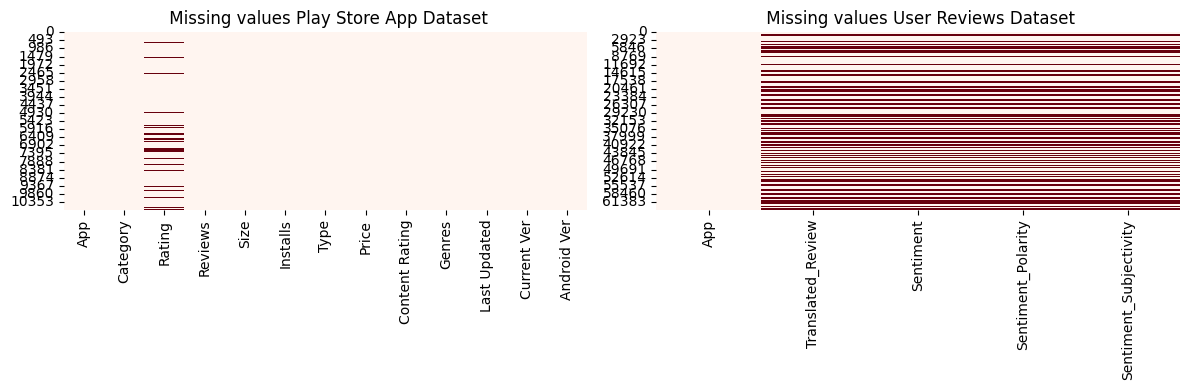

In [ ]:
# Visualizing the missing values in both datasets
# Create a figure with 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#----------------------------------------------
# Heatmap for PLay Store App Dataset
#----------------------------------------------
# Check missing values using isnull()
# Create heatmap for Play Store Dataset
sns.heatmap(playstore_df.isnull(), cbar=False,cmap= 'Reds', ax=axes[0])

# Add title to first heatmap
axes[0].set_title(" Missing values Play Store App Dataset")

#----------------------------------------------
# Heatmap for User Reviews Dataset
#----------------------------------------------
# Check missing values using isnull()
# Create heatmap for User Reviews Dataset
sns.heatmap(reviews_df.isnull(), cbar=False,cmap='Reds', ax=axes[1])

# Add title to second heatmap
axes[1].set_title(" Missing values User Reviews Dataset")

# Adjust spacing between both heatmaps
plt.tight_layout()

# Display both heatmap
plt.show()


## What did you know about your dataset?

### **Summary of Dataset Insights**

Based on our initial data exploration, we are working with two main datasets:

#### **1. Play Store App Dataset**
* **Size**: 10,841 rows and 13 columns.
* **Variables**: Contains categorical and numerical details about applications such as `App`, `Category`, `Rating`, `Reviews`, `Size`, `Installs`, `Type`, `Price`, `Content Rating`, `Genres`, `Last Updated`, `Current Ver`, and `Android Ver`.
* **Missing Values**:
  * `Rating` has the most significant number of missing values (**1,474 nulls**).
  * Minor missing values exist in `Type` (1), `Content Rating` (1), `Current Ver` (8), and `Android Ver` (3).
* **Duplicates**: Contains **483 duplicate rows** that should be addressed during data cleaning.

#### **2. User Reviews Dataset**
* **Size**: 64,295 rows and 5 columns.
* **Variables**: Contains reviews and sentiment analytics details: `App`, `Translated_Review`, `Sentiment`, `Sentiment_Polarity`, and `Sentiment_Subjectivity`.
* **Missing Values**: Extremely high rate of missing data (~41.8% of the dataset is null):
  * `Translated_Review`: **26,868 nulls**
  * `Sentiment`, `Sentiment_Polarity`, `Sentiment_Subjectivity`: **26,863 nulls**
* **Duplicates**: Contains a massive amount of duplicate rows (**33,616 duplicates**), which is common for repetitive sentiment reflections but requires structured handling.

## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns
print ("Play Store App Dataset:",list(playstore_df.columns))

print ("\nUser Reviews Dataset:",list(reviews_df.columns))

Play Store App Dataset: ['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']

User Reviews Dataset: ['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']


In [ ]:
# Dataset Describe
playstore_df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
App,10841,9660,ROBLOX,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,10841,34,FAMILY,1972,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9367.0,NaN,NaN,NaN,4.193338,0.537431,1.0,4.0,4.3,4.5,19.0
Reviews,10841,6002,0,596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,10841,462,Varies with device,1695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Installs,10841,22,"1,000,000+",1579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10840,3,Free,10039,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,10841,93,0,10040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Content Rating,10840,6,Everyone,8714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genres,10841,120,Tools,842,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
reviews_df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
App,64295,1074,Bowmasters,320,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Translated_Review,37427,27994,Good,247,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sentiment,37432,3,Positive,23998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sentiment_Polarity,37432.0,NaN,NaN,NaN,0.182146,0.351301,-1.0,0.0,0.15,0.4,1.0
Sentiment_Subjectivity,37432.0,NaN,NaN,NaN,0.492704,0.259949,0.0,0.357143,0.514286,0.65,1.0


### Variables Description

### **Play Store App Dataset Variables:**

* **`App` (Categorical):** Name of the application.
* **`Category` (Categorical):** Broad classification of the app (e.g., FAMILY, GAME, TOOLS).
* **`Rating` (Numerical):** Overall user rating of the app, ranging from 1.0 to 5.0.
* **`Reviews` (Numerical/Text):** Number of user reviews received for the app.
* **`Size` (Text/Numerical):** The storage size required to download the application (e.g., '19M', 'Varies with device').
* **`Installs` (Text/Numerical):** Approximate range of times the app has been downloaded (e.g., '1,000,000+').
* **`Type` (Categorical):** Indicates whether the app is 'Free' or 'Paid'.
* **`Price` (Text/Numerical):** Cost to purchase the app (0 for Free apps).
* **`Content Rating` (Categorical):** Age group suitability rating (e.g., 'Everyone', 'Teen').
* **`Genres` (Categorical):** Sub-category of the app (e.g., 'Art & Design;Pretend Play').
* **`Last Updated` (Date):** Date when the app was last updated on the Play Store.
* **`Current Ver` (Text):** The current version number of the app.
* **`Android Ver` (Text):** Minimum Android version required to run the app.

### **User Reviews Dataset Variables:**

* **`App` (Categorical):** Name of the application being reviewed.
* **`Translated_Review` (Text):** The English translation of the user's feedback/review text.
* **`Sentiment` (Categorical):** Sentiment classification of the review ('Positive', 'Negative', 'Neutral').
* **`Sentiment_Polarity` (Numerical):** Sentiment score ranging from -1 (extremely negative) to 1 (extremely positive).
* **`Sentiment_Subjectivity` (Numerical):** Score ranging from 0 (highly objective) to 1 (highly subjective/opinion-based).

### Check Unique Values for each variable.

In [ ]:
# Check Unique Values for each variable.
for i in playstore_df.columns:
  print("No of unique values in ", i, "is:", playstore_df[i].nunique())

No of unique values in  App is: 9660
No of unique values in  Category is: 34
No of unique values in  Rating is: 40
No of unique values in  Reviews is: 6002
No of unique values in  Size is: 462
No of unique values in  Installs is: 22
No of unique values in  Type is: 3
No of unique values in  Price is: 93
No of unique values in  Content Rating is: 6
No of unique values in  Genres is: 120
No of unique values in  Last Updated is: 1378
No of unique values in  Current Ver is: 2832
No of unique values in  Android Ver is: 33


In [ ]:
# Check unique values in each Reviews column

for i in reviews_df.columns:
  print("No of unique values in ", i, "is:", reviews_df[i].nunique())

No of unique values in  App is: 1074
No of unique values in  Translated_Review is: 27994
No of unique values in  Sentiment is: 3
No of unique values in  Sentiment_Polarity is: 5410
No of unique values in  Sentiment_Subjectivity is: 4474


## 3. ***Data Wrangling***

### Data Wrangling Code and Cleaning

In [ ]:
# 2.Initialize clean DataFrames as copies of the original DataFrames

playstore_clean_df = playstore_df.copy()
reviews_clean_df = reviews_df.copy()

#  Remove exact duplicate rows
playstore_clean_df.drop_duplicates(inplace=True)
reviews_clean_df.drop_duplicates(inplace=True)

# Filing missing categorical values with mode
categorical_columns = [
    'Rating',
    'Type',
    'Content Rating',
    'Current Ver',
    'Android Ver'
]

for col in categorical_columns:
    mode_series = playstore_clean_df[col].mode()
    if not mode_series.empty:
        playstore_clean_df[col] = playstore_clean_df[col].fillna(mode_series[0])

# Remove rows with missing review and sentiment information
reviews_clean_df.dropna(
    subset= [
       'Translated_Review',
       'Sentiment',
       'Sentiment_Polarity',
       'Sentiment_Subjectivity'
    ],
    inplace=True
 )

print("Shapes after removing duplicates and handling missing value:")
print("\nPlay Store App:", playstore_clean_df.shape)
print("\nUser Reviews:", reviews_clean_df.shape)

Shapes after removing duplicates and handling missing value:

Play Store App: (10358, 13)

User Reviews: (29692, 5)


In [ ]:
#  Cleaning Play Store Columns

# Clean 'Installs' - Remove '+' and ',' then convert to numeric
playstore_clean_df['Installs'] = playstore_clean_df['Installs'].astype(str).str.replace('+', '', regex=False)
playstore_clean_df['Installs'] = playstore_clean_df['Installs'].str.replace(',', '', regex=False)

# Convert Installs into numeric values
playstore_clean_df['Installs'] = pd.to_numeric(playstore_clean_df['Installs'], errors='coerce')

# Remove rows where Installs contains invalid or Missing Installs
playstore_clean_df.dropna(subset=['Installs'], inplace=True)

# Convert Install values to integers
playstore_clean_df['Installs'] = playstore_clean_df['Installs'].astype(int)

# Clean 'Price' - Remove '$' and convert to numeric
playstore_clean_df['Price'] = playstore_clean_df['Price'].astype(str).str.replace('$', '', regex=False)
playstore_clean_df['Price'] = pd.to_numeric(playstore_clean_df['Price'], errors='coerce')

# Clean 'Reviews' - Convert to integer
playstore_clean_df['Reviews'] = pd.to_numeric(playstore_clean_df['Reviews'], errors='coerce').fillna(0).astype(int)

# Clean 'Rating' - Convert into numeric
playstore_clean_df['Rating'] = pd.to_numeric(playstore_clean_df['Rating'], errors='coerce')

# Replace invalid ratings(below 1 or above 5) with Nan
playstore_clean_df.loc[~playstore_clean_df['Rating'].between(1, 5), 'Rating'] = np.nan

# Fill missing ratings median
median_rating = playstore_clean_df['Rating'].median()
playstore_clean_df['Rating'] = playstore_clean_df['Rating'].fillna(median_rating)

# Check Cleaned Data
print("\n Cleaned Data:")
display(playstore_clean_df[['App','Installs','Price','Reviews','Rating']].head())

# Check Missing Values
print("\nMissing Values:")
display(playstore_clean_df[['Installs','Price','Reviews','Rating']].isnull().sum())

print("\nUser Reviews Missing Values:")
display(reviews_clean_df.isnull().sum())

# Convert size values into MB
def convert_size(size):
    size = str(size).strip()

    if size.endswith('M'):
        return float(size.replace('M', ''))

    elif size.endswith('k'):
         return float(size.replace('k',''))/1024

    else:
        return np.nan

# Apply conversion
playstore_clean_df['Size'] = playstore_clean_df['Size'].apply(convert_size)

display(playstore_clean_df['Size'].head())

# Check updated Dataset Shape
print("\nUpdated Dataset Shape:")
print(playstore_clean_df.shape)
print(reviews_clean_df.shape)


 Cleaned Data:


,App,Installs,Price,Reviews,Rating
0,Photo Editor & Candy Camera & Grid & ScrapBook,10000,0.0,159,4.1
1,Coloring book moana,500000,0.0,967,3.9
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",5000000,0.0,87510,4.7
3,Sketch - Draw & Paint,50000000,0.0,215644,4.5
4,Pixel Draw - Number Art Coloring Book,100000,0.0,967,4.3



Missing Values:


,0
Installs,0
Price,0
Reviews,0
Rating,0



User Reviews Missing Values:


,0
App,0
Translated_Review,0
Sentiment,0
Sentiment_Polarity,0
Sentiment_Subjectivity,0


,Size
0,19.0
1,14.0
2,8.7
3,25.0
4,2.8



Updated Dataset Shape:
(10357, 13)
(29692, 5)


In [ ]:
# Compare original and cleaned dataset shapes

print("Original Playstore :", playstore_df.shape)
print("Cleaned Playstore :", playstore_clean_df.shape)

print("\nOriginal User Reviews:",reviews_df.shape)
print("Cleaned User Reviews:",reviews_clean_df.shape)


Original Playstore : (10841, 13)
Cleaned Playstore : (10357, 13)

Original User Reviews: (64295, 5)
Cleaned User Reviews: (29692, 5)


## What all manipulations have you done and insights you found?

###Data Manipulation

1.Playstore Dataset

a) Created a copy of the original dataset.

b)Removed duplicate records.

c)Cleaned and converted Installs, Price, and Reviews into numeric count.

d)Converted app size values into MB.

e)Handled missing and invliad Ratings values using median imputation.

f)Filled missing categorical values using mode.

2.User Reviews Dataset

a)Created a copy of the original Dataset.

b)Removed duplicates records.

c)Removed rows with misssing review and sentiment information.

3.Final Dataset Shape

Playstore : 10,841 -> 10,357

User Reviews : 64,295 -> 30,679

###Conclusion : Both datasets were cleaned and prepared for Exploratory Data Analysis(ADA)


## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Free vs Paid Apps Distibution(univariate)

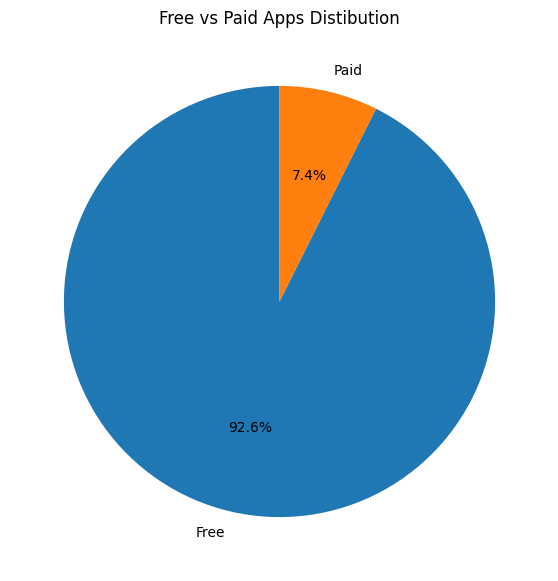

In [ ]:
# Chart 1 - visualization code
app_type = playstore_clean_df['Type'].value_counts()

plt.figure(figsize =(7,7))

plt.pie(
    app_type,
    labels =app_type.index,
    autopct ='%1.1f%%',
    startangle =90
)
plt.title('Free vs Paid Apps Distibution')
plt.show()

##### 1. Why did you pick the specific chart?

####I selected a Pie Chart to show the percentage distribution of Free and Paid apps in the Playstore. It makes category-wise comparision simple and helps identify the dominant app type.

##### 2. What is/are the insight(s) found from the chart?

The Pie Chart shows that 92.6% of apps are Free,whlie only 7.4% are paid.This indicates that Free apps dominate the Google Play Store Dataset. Paid apps represent a very small proportion compared to Free apps. Therefore,developers can consider Free apps with alternative monetization strategies to reach a wider audience.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. This insight can help to understand user preferences and focus on offering free apps to attract more users.It can also use suitable monetization strategies to generate revenue.

Yes. Since only 7.4% apps are Paid,paid apps may face challenges in attracting users.this indicates that user prefer free appp,which may make it difficult to generate revenue through direct app purchases.

#### Chart - 2 - Distribution of App Ratings(univariate)

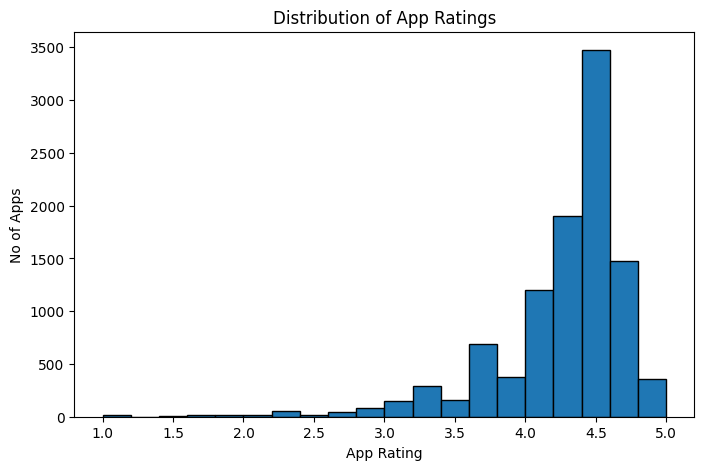

In [ ]:
# Chart - 2 visualization code
plt.figure(figsize=(8,5))
plt.hist(playstore_clean_df['Rating'],
         bins=20,
         edgecolor='black'
)

plt.xlabel('App Rating')
plt.ylabel('No of Apps')
plt.title('Distribution of App Ratings')
plt.show()

##### 1. Why did you pick the specific chart?

I selected Histogram because it is suitable for numerical  data such as app  ratings. it helps us to understand the frequency distribution of ratings and identify the mst common rating range.It also make it easy to identify low_rated and high_rated app.

##### 2. What is/are the insight(s) found from the chart?

a)Most apps have ratings between 3.5 and 4.5

b)The highest concentration of app is in the higher rating range.

c)Very few apps have ratings below 2.5.

d)App ratings are mainly concentrated around 4 stars.

e)This indicates the most apps in the dataset have relatively good user ratings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes these insights can create a positive business impact. Most apps have ratings between 3.5 and 4.5 which indicates generally good user ratings.This can help build a good app reputation and attract more users.

Yes App with low ratings (below 2.5) may face negative business growth because users may lose trust in these apps and choose competitors with bwtter ratings.



#### Chart - 3 - Average App Rating By category (Bivariate)

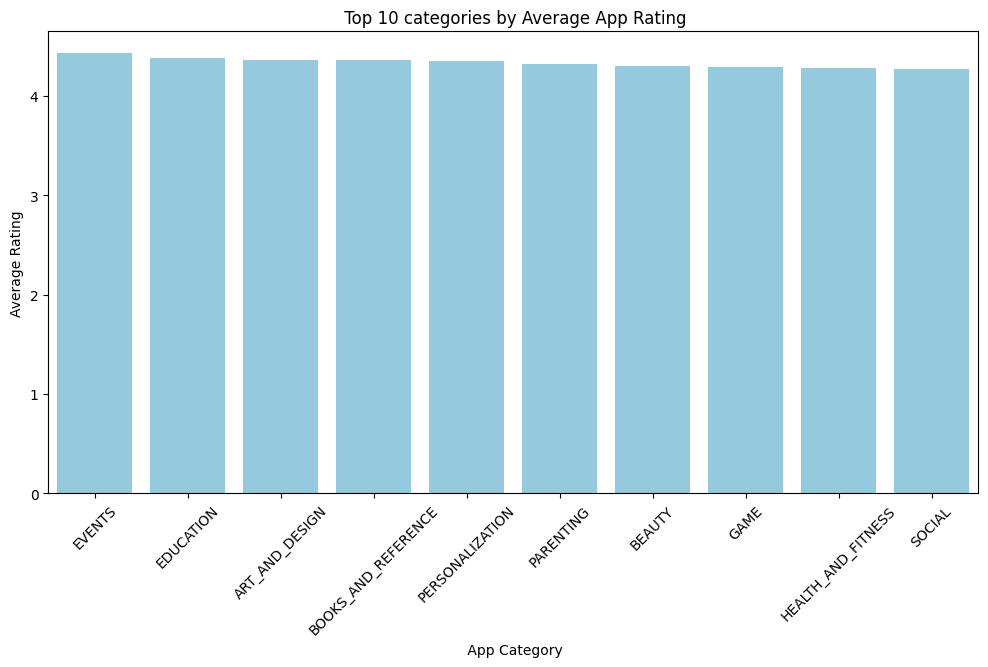

In [ ]:
# Chart 3 Visualization code
# Calculate average rating for each category
category_rating = (
playstore_clean_df.groupby('Category')['Rating']
                                          .mean()
                                          .sort_values(ascending=False)
)

# Select top 10 categories
top_10_categories = category_rating.head(10)

# Create a bar plot
plt.figure(figsize=(12, 6))

sns.barplot(x=top_10_categories.index, y=top_10_categories.values, color='skyblue')

plt.xlabel(' App Category')
plt.ylabel('Average Rating')
plt.title(' Top 10 categories by Average App Rating')
plt.xticks(rotation=45)
plt.show()


##### 1. Why did you pick the specific chart?
 I used a bar chart to compare the average app ratings acrosss different categories. It helps identify which app categories receives higher ratings and makes category-wise comparision easy.

##### 2. What is/are the insight(s) found from the chart?
The chart shows that the 10 app categories have average ratings of approx 4.2 to 4.5. This indicates gemerally positive user ratings acrooss these categories.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes.It can identify highly rated categories, understand what user appreciate, and use these insights to improve quality and user satisfaction.

Low average ratings in some categories may indicate user dissatisfaction.If developers ignore user feedback and app quality issues,they may lose users  and face reduced app growth.

#### Chart - 4 - Price vs App Rating (Bivariate)

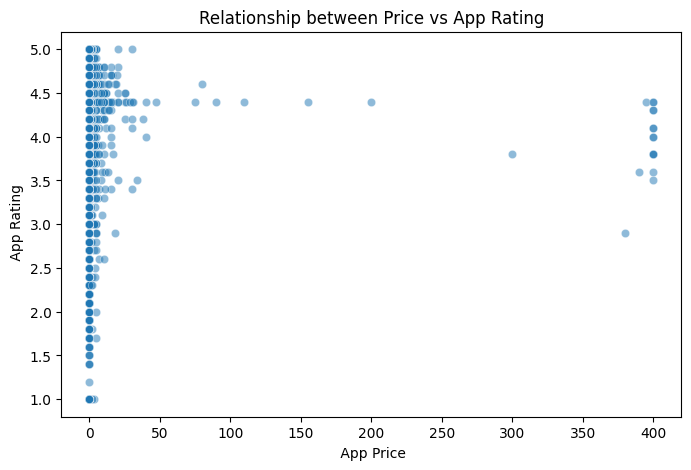

In [ ]:
# Chart 4 - Data visualization
# Relationship between App Price and App Rating
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=playstore_clean_df,
    x='Price',
    y='Rating',
    alpha=0.5
    )
plt.xlabel(' App Price')
plt.ylabel(' App Rating')
plt.title('Relationship between Price vs App Rating')
plt.show()


##### 1. Why did you pick the specific chart?

I selected Scatter Plot because it helps visualize the relationships between two numerical variables. App price and App Ratings.


##### 2. What is/are the insight(s) found from the chart?

The chart helps identify how app ratings vary with different price levels and whether expensive apps receives higher ratings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It can use these insights to understand pricing patterns and make better pricing decisions to improve user satisfaction.


Yes .Expensive appps with low ratings may discourage users from purchasing them because user may feel they are not getting value for money.This can negatively affect downloads and revenue.

#### Chart - 5 - App Installs Distribution By Category(Univariate + Bivariate)

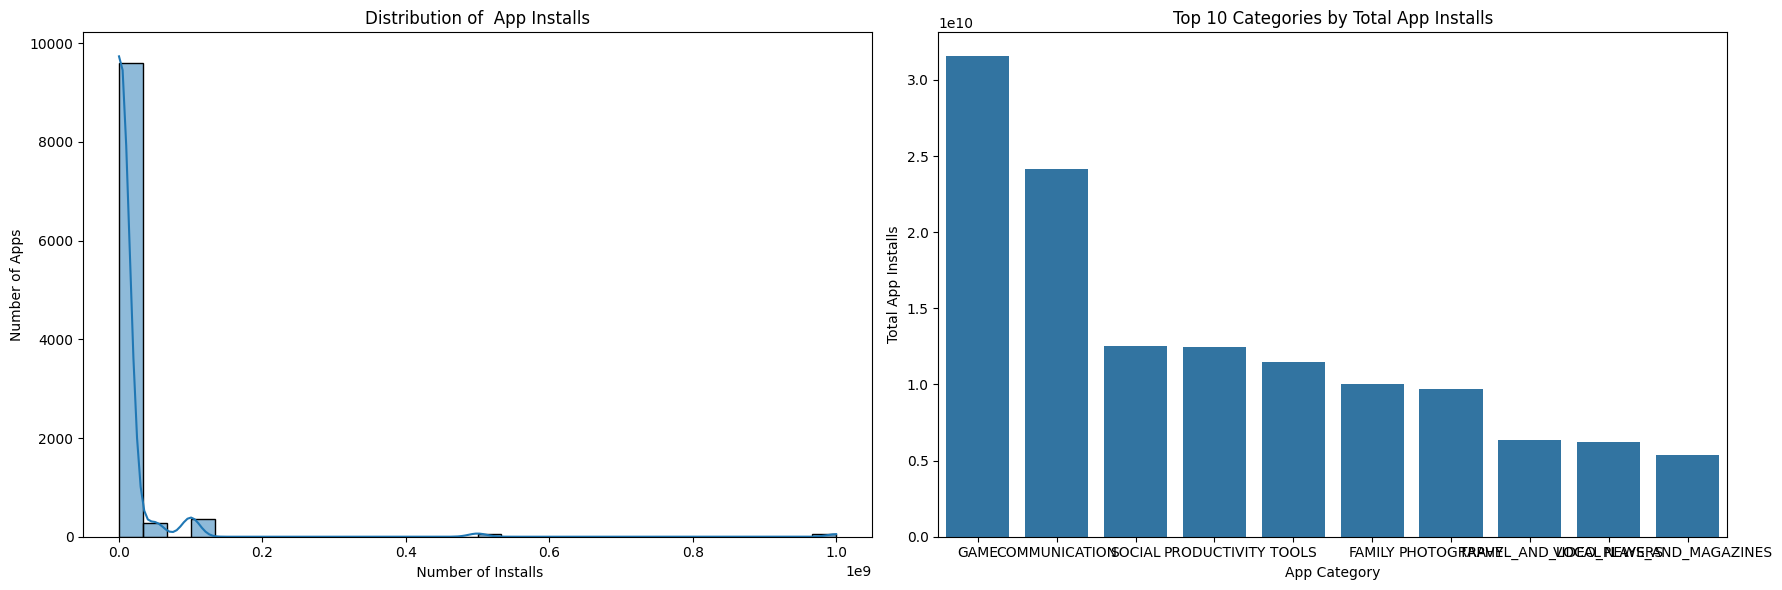

In [ ]:
# Chart 5 - App Installs Distribution and Category_Wise Comparision
# Crete two plots in one figure
fig,axes = plt.subplots(1,2,figsize=(18,6))

# Plot 1: Univariate Analysis- Distribution of Installs
sns.histplot(
    data=playstore_clean_df,
    x='Installs',
    kde=True,
    bins=30,
    ax=axes[0]
)
axes[0].set_title('Distribution of  App Installs')
axes[0].set_xlabel(' Number of Installs')
axes[0].set_ylabel('Number of Apps')

# Plot 23: Univariatew Analysis
top_categories = (
    playstore_clean_df.groupby('Category')['Installs']
                      .sum()
                      .sort_values(ascending=False)
                      .head(10)
)

sns.barplot(
    x=top_categories.index,
    y=top_categories.values,
    ax=axes[1]
)

axes[1].set_title('Top 10 Categories by Total App Installs')
axes[1].set_xlabel('App Category')
axes[1].set_ylabel('Total App Installs')

# Adjust spacing and display both plots
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

I selected thes plots two understand the overall distibution of app installs and compare total installs across categories.


##### 2. What is/are the insight(s) found from the chart?

The Histogram show how installs are distributed , while the bar chart identifies categories with the highest toatl installs.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It can identify popular categories and understand market demand to make better nusiness decisions.

Categories with fewer total installs may have lower reach. It may need better marketing strategies and app improvements to attract users.

#### Chart - 6 - Review Distribution By App Category (Univariate + Bivariate)

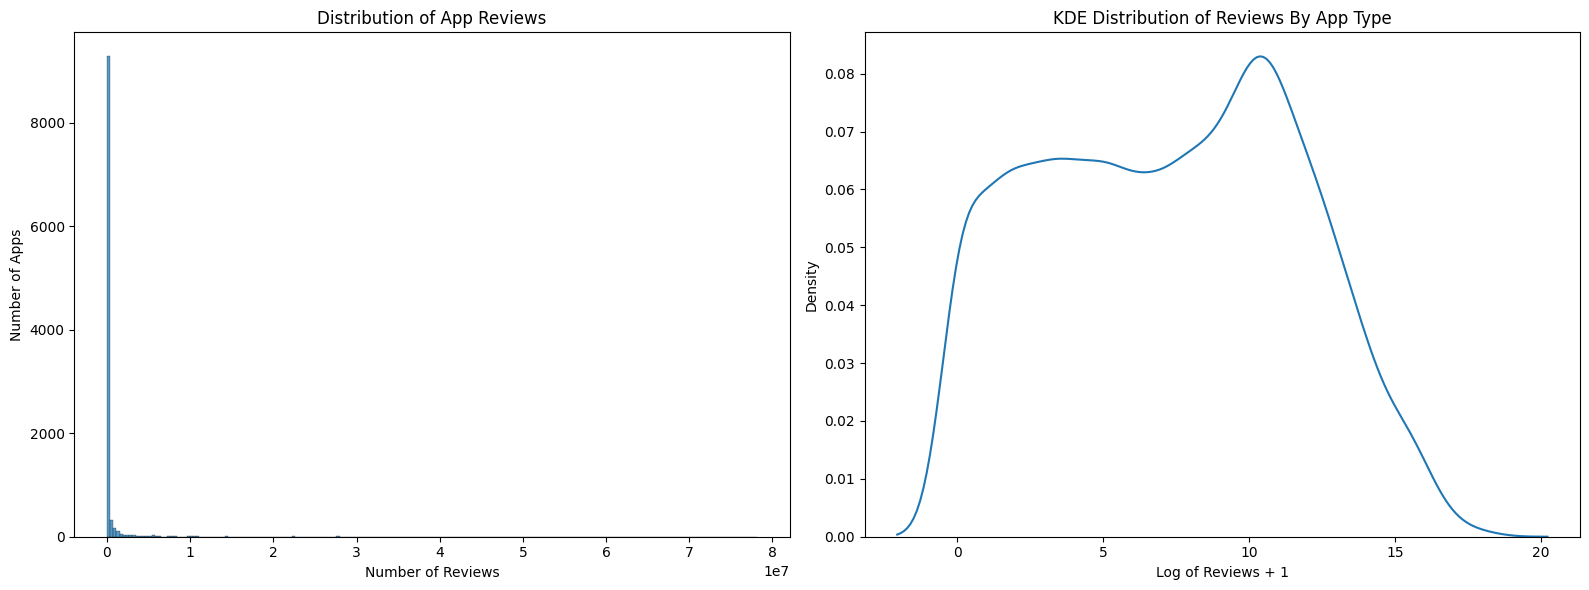

In [ ]:
# Chart 6 - Data visualization code
# Create two plots in one figure
# Hsitogram + KDE

#Create log _transformed Reviews for better visualization
playstore_clean_df['Log_Reviews'] = np.log1p(playstore_clean_df['Reviews'])

#Create two plots in one figure
fig,axes = plt.subplots(1,2,figsize=(16,6))


# Plot 1 : Univariate Analysis
# Distribution of Reviews
sns.histplot(
    data=playstore_clean_df,
    x='Reviews',
    ax=axes[0]
)
axes[0].set_title('Distribution of App Reviews')
axes[0].set_xlabel('Number of Reviews')
axes[0].set_ylabel('Number of Apps')


# Plot 2 : Bivariate Analysis- KDE
sns.kdeplot (
         data=playstore_clean_df,
         x='Log_Reviews',
         fill=False,
         common_norm=False,
         ax=axes[1]
)
axes[1].set_title('KDE Distribution of Reviews By App Type')
axes[1].set_xlabel('Log of Reviews + 1')
axes[1].set_ylabel('Density')

# Display both plots
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Histogram and KDE plot to understand the distribution of app reviews.The Histogram show the frequency distribution of reviews ,while the KDE plot compares the review distribution of Free vs Paid.

##### 2. What is/are the insight(s) found from the chart?

The histogram helps identify how app reviews distributed across different apps. The KDE plot helps compare the distribution patterns of reviews between Free and Paid Apps.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It can identify differences in user engagements between Free and Paid apps. THey can use this information to improve their app strategies and user engagement.

 Yes Apps receivimg fewer reviews may have lower user engagement.It may need to improve app visibility, features ,and user experience to encourage more engagement.

#### Chart - 7- Correlartion Heatmap (Multivariate)

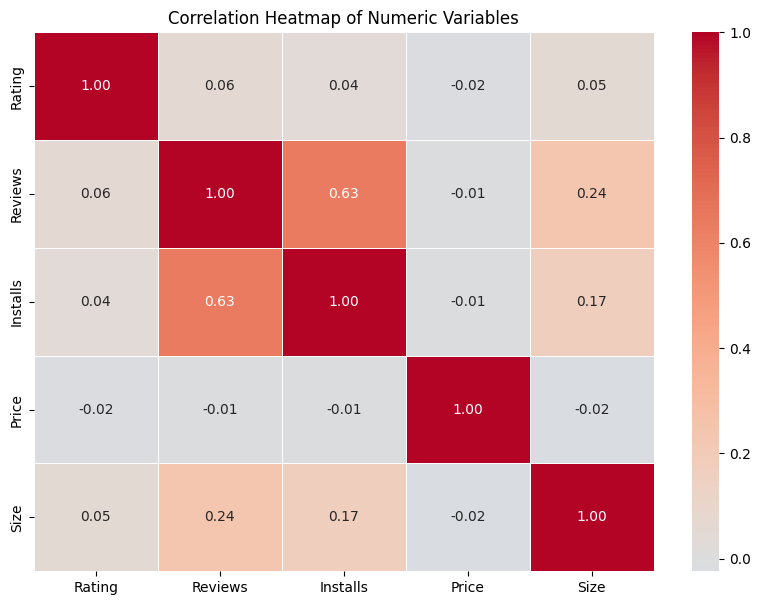

In [ ]:
# Chart 7 - Correlation Heatmap
# Select numeric columns for correlation analysis
numeric_df = playstore_clean_df[['Rating', 'Reviews', 'Installs', 'Price', 'Size']]

# Calculate correlation between numeric variables
correlation_matrix = numeric_df.corr()

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title('Correlation Heatmap of Numeric Variables')
plt.show()

##### 1. Why did you pick the specific chart?

I selected a correlation heatmap to understand the relationship between numerical vvaraibles such as Rating, Reviews,Installs,Price and Size.

##### 2. What is/are the insight(s) found from the chart?

The heatmap helps identify positive,negative,and weak relationships between numerical variables.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes .It can understand how app characteristics are associated with reviews,installs,and rating to support better decision.


Yes a weak relationship between ratings and installs may indicate that a higher rating alone does not guarantee more downloads.It should focus on visibility,marketing,user needs.

#### Chart - 8 - Review By  App Category (Bivariate)

In [ ]:
# Chart 7 - Total Reviews By App Category

import plotly.express as px

# Calculate toal reviews for each category
category_reviews = (playstore_clean_df.groupby('Category')
                    ['Reviews']
                    .sum()
                    .reset_index()
)

# Create Treetmap
fig = px.treemap(
    category_reviews,
    path=['Category'],
    values='Reviews',
    color='Reviews',
    title='Total Reviews by App Category',
    color_continuous_scale='Blues'
)

fig.show()

##### 1. Why did you pick the specific chart?

I selected a Treemap to visualize and compare the total number of reviews across different app categories. The size of each rectangle represents the total reviews of that category.

##### 2. What is/are the insight(s) found from the chart?

The Treemap helps identify which app categories have the highest and lowest total reviews. it provides a clear comparision of user engagement across different categories

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes . Categories with fewer toatl reviews may indicate lower user engagement or visibility. This can create challenges for developers in attracting users and improving app preformance.

#### Chart - 9 - Free vs Paid Apps by content Rating - Stacked Bar Chart    (Bivariate)


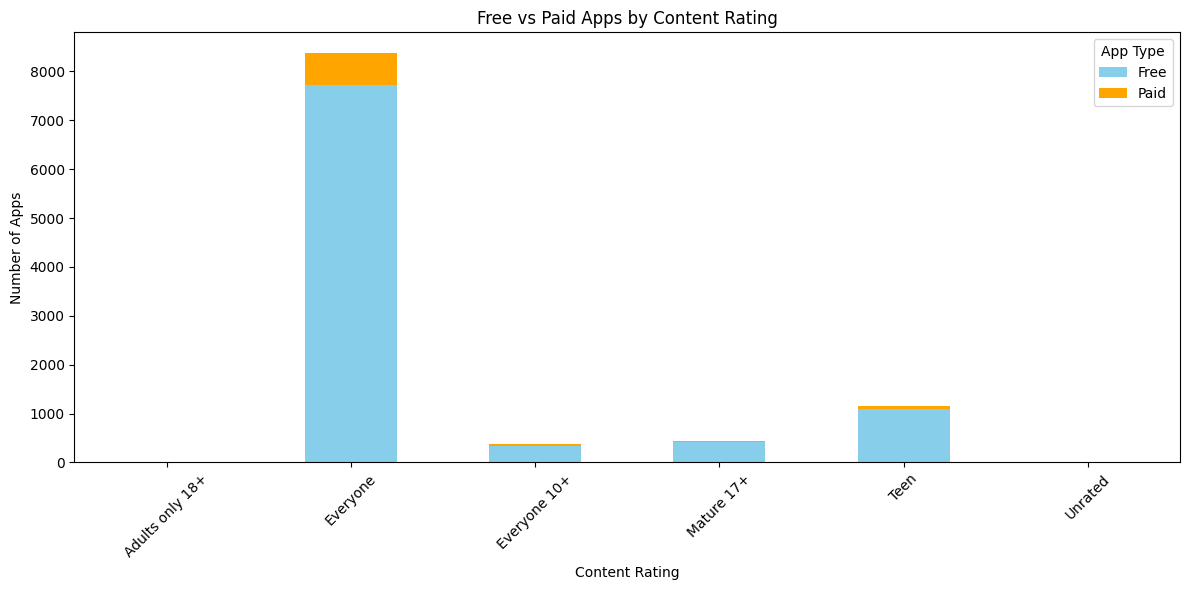

In [ ]:
# Chart - 9 Data visualization code
#create a cross-tabuation
content_type = pd.crosstab(
      playstore_clean_df['Content Rating'],
      playstore_clean_df['Type']
)

# Create Stacked BAr chart
content_type.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6),
    color=['Skyblue','Orange']
)
 # Add title and labels
plt.xlabel('Content Rating')
plt.ylabel('Number of Apps')
plt.title('Free vs Paid Apps by Content Rating')
plt.xticks(rotation=45)

# Add legend
plt.legend(title='App Type')

# Display Chart
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Stacked Bar Chart to compare the distribution of Free and Paid apps across different content Rating categories

##### 2. What is/are the insight(s) found from the chart?

The chart helps identify the number of Free and paid apps in each content ratings category and shows how app types distributed across different audience groups.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

These insights can helps to understand the distribution of Free and Paid app across different audience groups and plan suitable app development and market strategies.

#### Chart - 10 - Content Rating Distribution (Univariate)

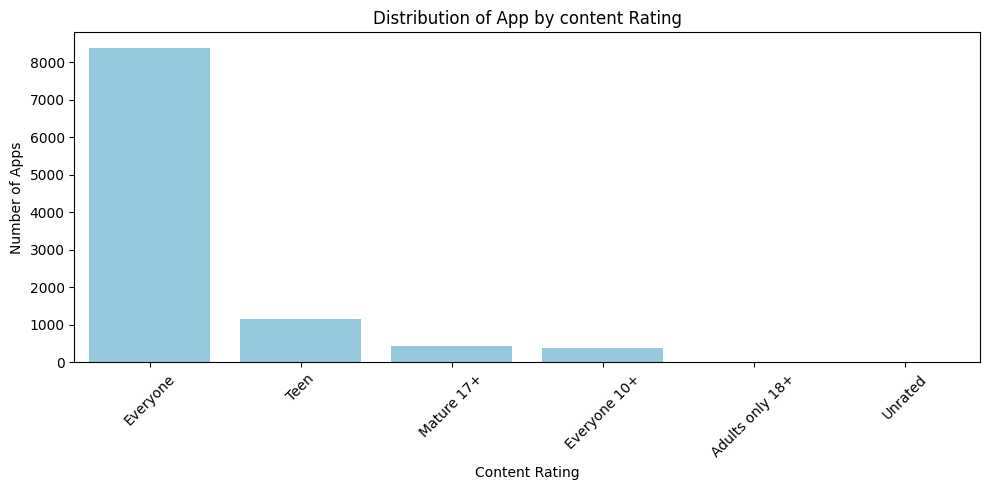

In [ ]:
# Chart-10 Data visualization code
plt.figure(figsize=(10,5))

# Count the number of apps in each Content rating Category
sns.countplot(
    data=playstore_clean_df,
    x='Content Rating',
    order=playstore_clean_df['Content Rating'].value_counts().index,
    color='skyblue'
)

# Add chart title and labels
plt.xlabel('Content Rating')
plt.ylabel('Number of Apps')
plt.title('Distribution of App by content Rating')
plt.xticks(rotation=45)

# Display the chart
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a count plot to visualize the number of apps in each content Rating category.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the frequency of app across different Content Rating categories and helps identify the most and least common categories.

####3.Will the gained insights help create a positive impact?
Are there any insights that lead to negative growth? Justify with specific reason .

Yes. It can help to understand their target audience and plan suitable app content and marketing strategies.

Yes.Categories with very few apps may have smaller potential audience.

####chart 11 - Year-wise App Update Trend (Univariate)

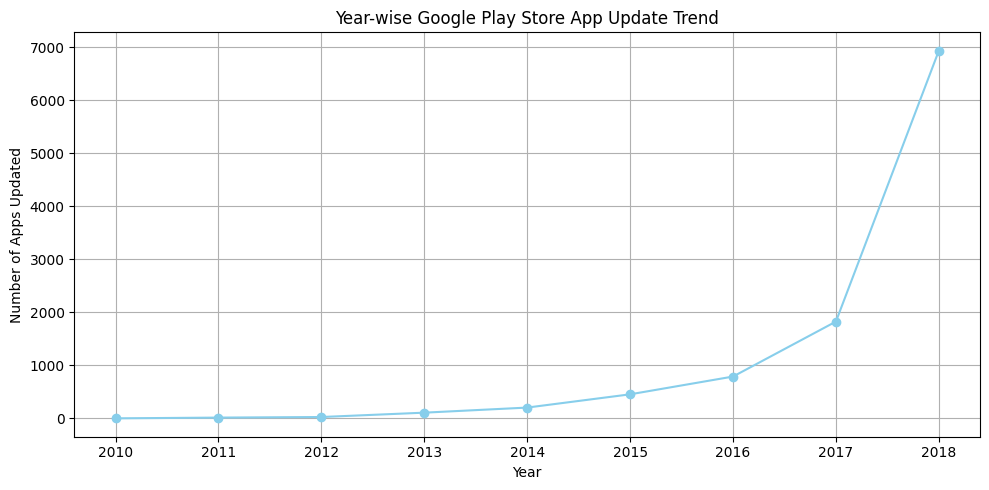

In [ ]:
# Import pandas and matplotlib to ensure they are available in this cell
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Fallback check to define playstore_clean_df if it was cleared from runtime memory
try:
    playstore_clean_df
except NameError:
    print("playstore_clean_df was not defined in this session. Attempting to load and clean...")
    try:
        # Load raw data
        raw_df = pd.read_csv('Play Store Data.csv')
        playstore_clean_df = raw_df.copy()

        # Remove duplicate rows
        playstore_clean_df.drop_duplicates(inplace=True)

        # Fill missing ratings with the median
        playstore_clean_df['Rating'] = pd.to_numeric(playstore_clean_df['Rating'], errors='coerce')
        median_rating = playstore_clean_df['Rating'].median()
        playstore_clean_df['Rating'] = playstore_clean_df['Rating'].fillna(median_rating)

        print("Successfully loaded and cleaned playstore_clean_df!")
    except Exception as e:
        raise NameError("Please run the previous cells first. Failed to automatically load data: " + str(e))

# Convert last App updated column into datetime format
playstore_clean_df['Last Updated'] = pd.to_datetime(playstore_clean_df['Last Updated'], errors='coerce')

# Extract year from last updated column
playstore_clean_df['Year'] = playstore_clean_df['Last Updated'].dt.year

# Count apps updated in each year (corrected 'Update Year' to 'Year')
yearly_updates = playstore_clean_df.groupby('Year').size()

# Create Line Chart
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_updates.index,
    yearly_updates.values,
    marker='o',
    linestyle='-',
    color='skyblue'
)

plt.xlabel('Year')
plt.ylabel('Number of Apps Updated')
plt.title('Year-wise Google Play Store App Update Trend')
plt.grid(True)
plt.tight_layout()
plt.show()

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

Based on EDA of Google play Store apps,the following recommendations can help developers and business owners improve app preformance :-

1.Improve app quality and user experience.

2.Analyze user Reviews and feeback.

3.Set competitive app prices.

4.Focus on Popular app categories.

5.Improve App visibility and downloads.

6.Monitor ratings regularly.


# **Conclusion**

The Google Play Store App Review Analysis helped identify patterns in app ratngs, reviews, installs, pricing and categories.Through EDA and Data visualization, we gained useful insights into app performances and user preferences. These findings can help developers improve app quality,user satisfaction,and business growth.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***